# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael 
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

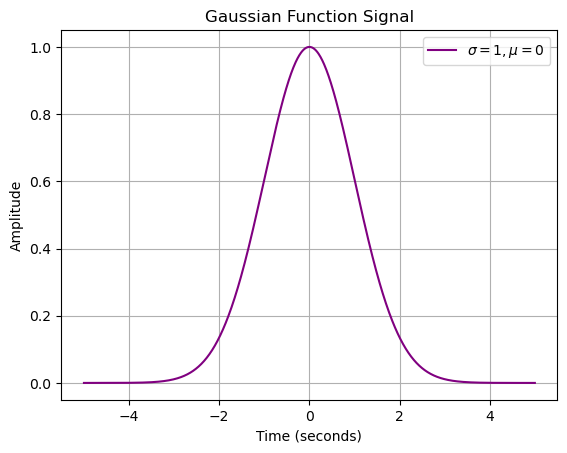

In [2]:
# this is just a test
from scipy import signal

# time array
t = np.linspace(-5, 5, 1000)

# Gaussian parameters
mu = 0 # mean (center of the peak)
sigma  = 1 # standard deviation (controls width)

# calculate gaussian signal
gaussian_signal = np.exp( -0.5 * ((t - mu) / sigma) ** 2)

# Plot the signal
plt.plot(t, gaussian_signal, label=r"$\sigma=1, \mu=0$", color="purple")
plt.title("Gaussian Function Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.savefig("gaussian.png", dpi=300, bbox_inches='tight')
plt.show()

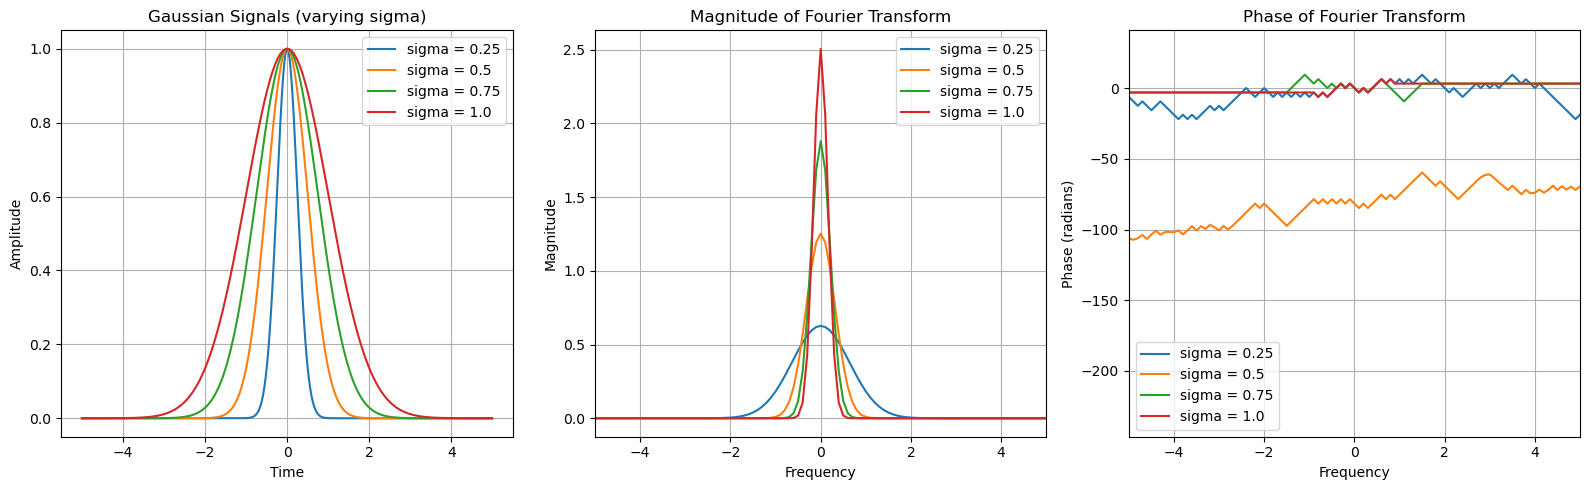

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

N = 1000
t = np.linspace(-5, 5, N, endpoint=False)
dt = t[1] - t[0]

sigmas = [0.25, 0.5, 0.75, 1.00]

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

for sigma in sigmas:
    signal = np.exp(-t**2 / (2*sigma**2))

    # fourier transform
    fft = np.fft.fftshift(np.fft.fft(signal))
    freq = np.fft.fftshift(np.fft.fftfreq(N, dt))
    
    # corrcts large jumps, restoring smoothness 
    ax[0].plot(t, signal, label=f'sigma = {sigma}')
    ax[1].plot(freq, np.unwrap(abs(fft)*dt), label=f'sigma = {sigma}')
    ax[2].plot(freq, np.unwrap(np.angle(fft)), label=f'sigma = {sigma}')

ax[0].set_title('Gaussian Signals (varying sigma)')
ax[0].set_xlabel('Time')
ax[0].set_ylabel('Amplitude')

ax[1].set_title('Magnitude of Fourier Transform')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Magnitude')
ax[1].set_xlim(-5, 5)

ax[2].set_title('Phase of Fourier Transform')
ax[2].set_xlabel('Frequency')
ax[2].set_ylabel('Phase (radians)')
ax[2].set_xlim(-5, 5)

for a in ax:
    a.legend()
    a.grid()

plt.tight_layout()
plt.savefig("prob1.png", dpi=300, bbox_inches='tight')
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


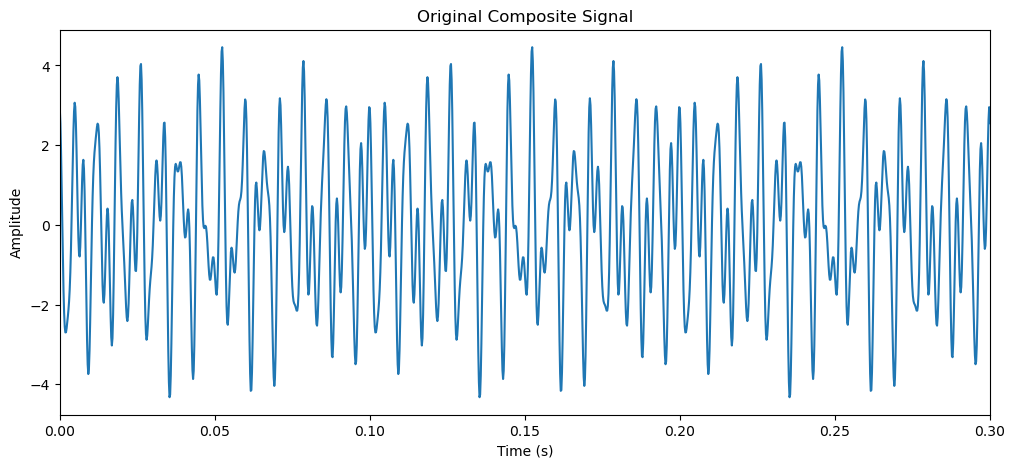

In [4]:
# Make a wave (combo of sine and cosine waves with varying amplitudes)
N = 25000
dt = 0.0002 # if spacing is 0.0002, then frequency is 5000 Hz
t_ = np.arange(N)*dt

# Creating a composite signal from 3 distinct waves
wave1 = 2.0 * np.cos(2 * np.pi * 150 * t_ + np.pi/3)
wave2 = 1.5 * np.sin(2 * np.pi * 270 * t_ + np.pi/4)
wave3 = 1.0 * np.cos(2 * np.pi * 380 * t_ + np.pi/6)

signal_original = wave1 + wave2 + wave3

# Plot original signal to verify
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0, 0.3)
ax.set_title("Original Composite Signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
plt.savefig("prob2_1.png", dpi=300, bbox_inches='tight')

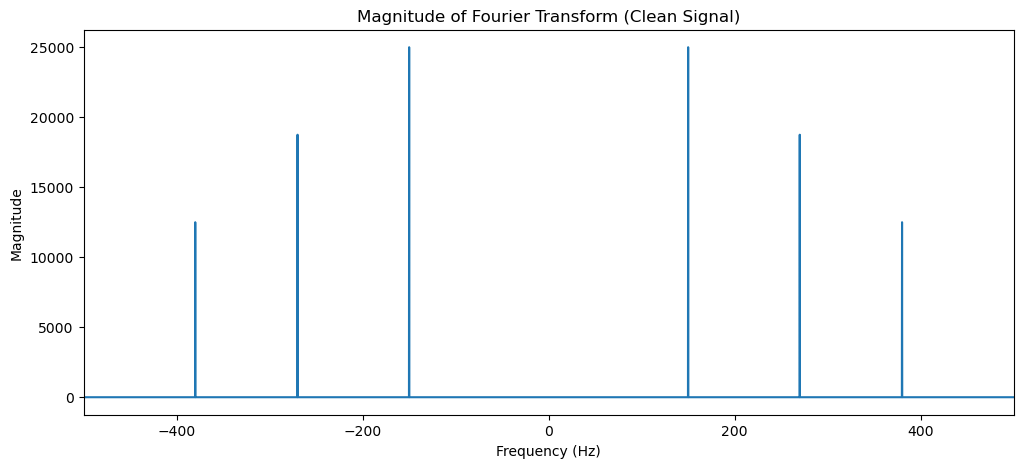

In [5]:
# FILL: Plot the fourier transform of the clean, original signal
cleanFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))
cleanPeaks = np.abs(np.fft.fftshift(np.fft.fft(signal_original)))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(cleanFreqs, cleanPeaks)
ax.set_xlim(-500, 500) 
ax.set_title("Magnitude of Fourier Transform (Clean Signal)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
plt.savefig("prob2_2.png", dpi=300, bbox_inches='tight')

In [6]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

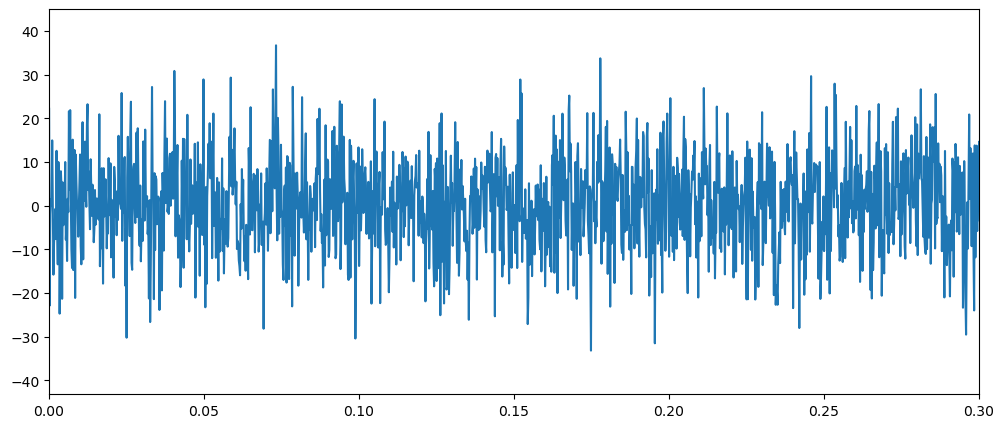

In [7]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)
plt.savefig("prob2_3.png", dpi=300, bbox_inches='tight')

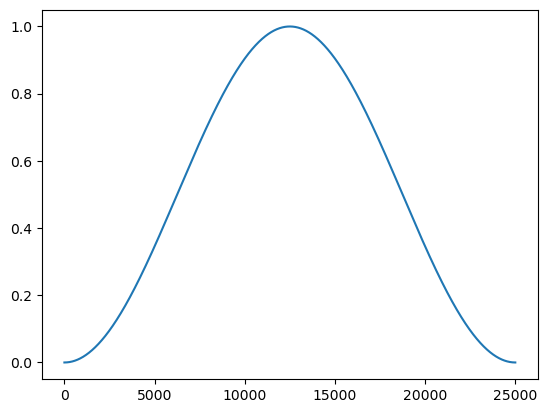

In [8]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)
plt.savefig("prob2_4.png", dpi=300, bbox_inches='tight')

In [10]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


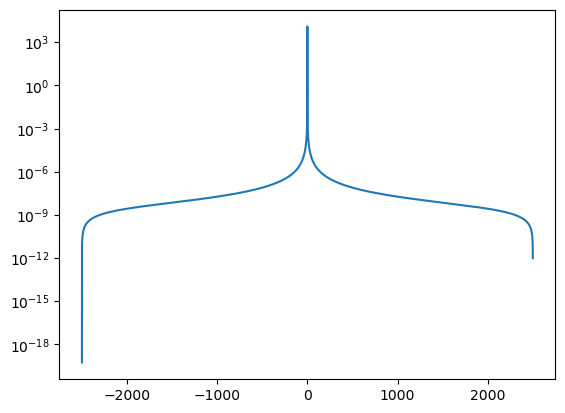

In [11]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
plt.savefig("prob2_5.png", dpi=300, bbox_inches='tight')

In [12]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


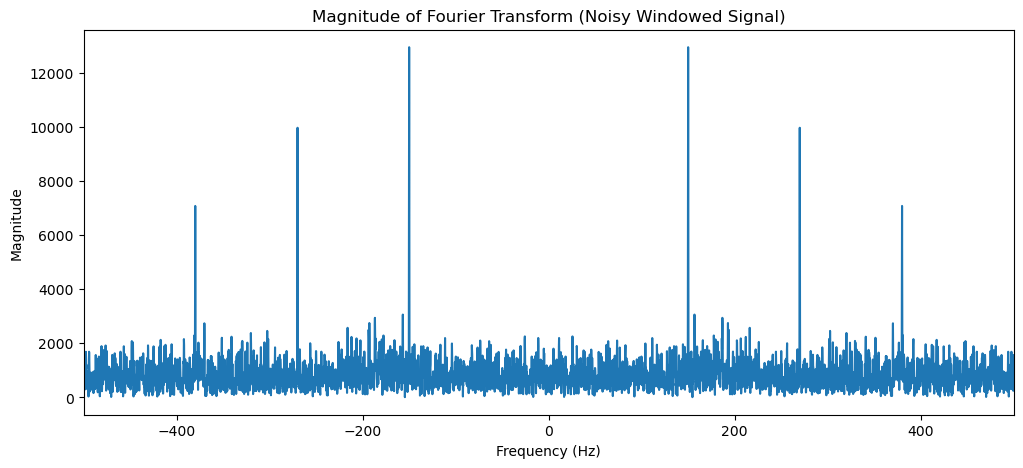

In [13]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
noisySigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))
noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(noisySigFreqs, noisySigPeaks)
ax.set_xlim(-500, 500)
ax.set_title("Magnitude of Fourier Transform (Noisy Windowed Signal)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
plt.savefig("prob2_6.png", dpi=300, bbox_inches='tight')

In [14]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
# A threshold of 4000 safely clears the noise floor while keeping the main frequency spikes
threshold = 4000 
cleanedFourier = noisyFourier.copy()

for i in range(len(cleanedFourier)):
    if np.abs(cleanedFourier[i]) < threshold:
        cleanedFourier[i] = 0

In [15]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
# Apply Inverse FFT and take the real component
recovered_windowed = np.real(np.fft.ifft(cleanedFourier))



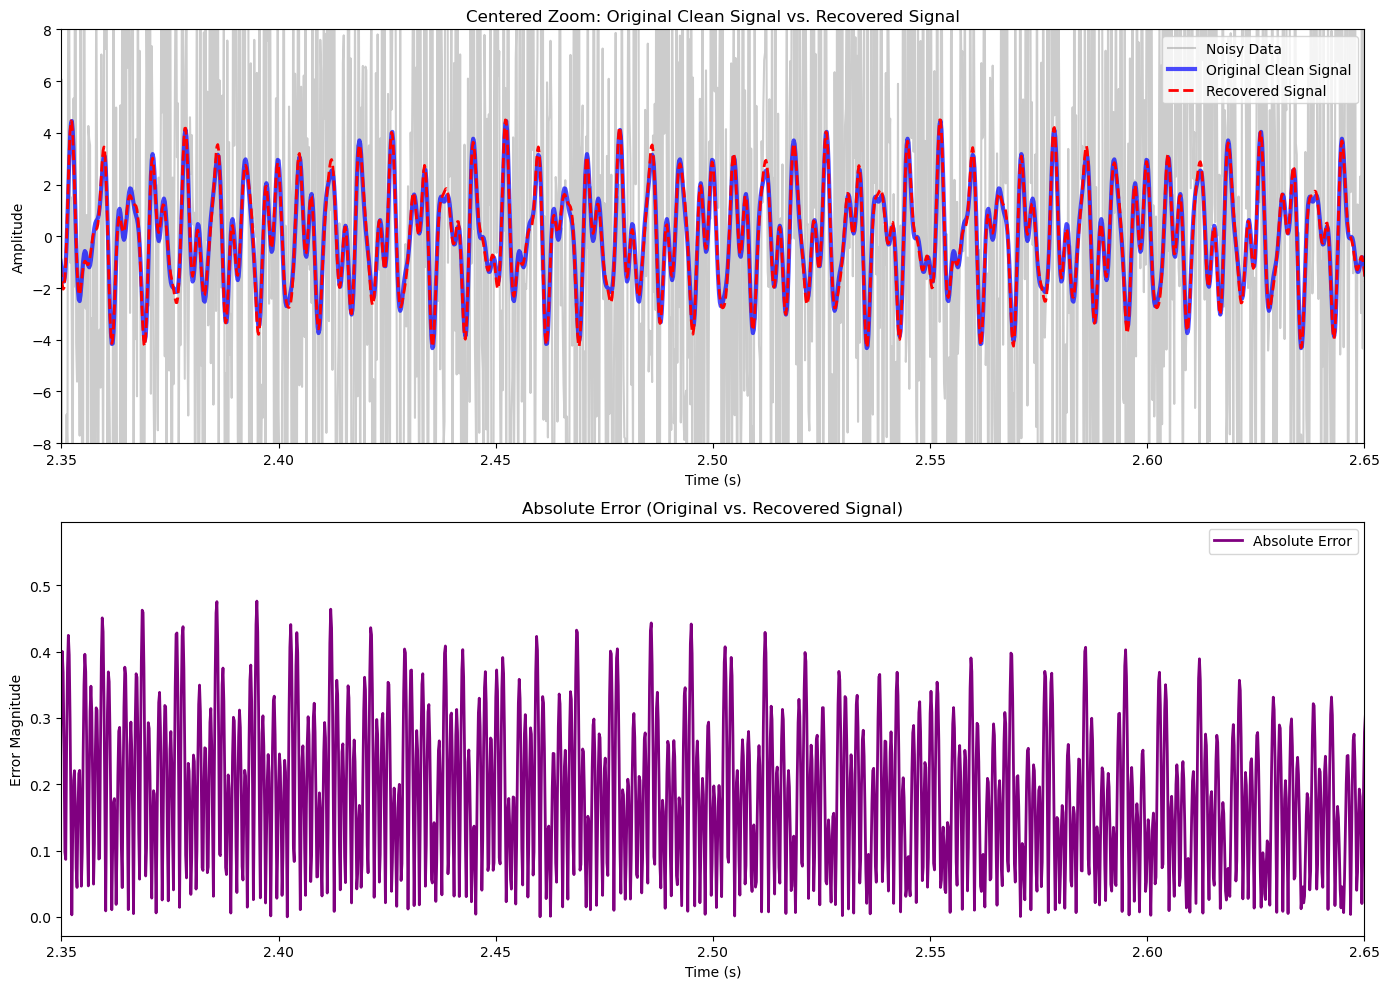

In [19]:
threshold = 2800 
cleanedFourier = noisyFourier.copy()
cleanedFourier[np.abs(cleanedFourier) < threshold] = 0


recoveredSignal = np.real(np.fft.ifft(cleanedFourier))


absolute_error = np.abs((signal_original * window) - recoveredSignal)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))


ax1.plot(t_, noisy_data, color='gray', alpha=0.4, label="Noisy Data")
# In this centered zoom, the window is 1.0, so the original signal overlaps perfectly
ax1.plot(t_, signal_original, color='blue', alpha=0.7, linewidth=3, label="Original Clean Signal")
ax1.plot(t_, recoveredSignal, color='red', linestyle='--', linewidth=2, label="Recovered Signal")

ax1.set_xlim(2.35, 2.65) 
ax1.set_ylim(-8, 8) 
ax1.set_title("Centered Zoom: Original Clean Signal vs. Recovered Signal")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
ax1.legend(loc="upper right")

# 2. Absolute Error Plot
ax2.plot(t_, absolute_error, color='purple', linewidth=2, label="Absolute Error")

ax2.set_xlim(2.35, 2.65) 
ax2.set_title("Absolute Error (Original vs. Recovered Signal)")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Error Magnitude")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("prob2_7.png", dpi=300, bbox_inches='tight')
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

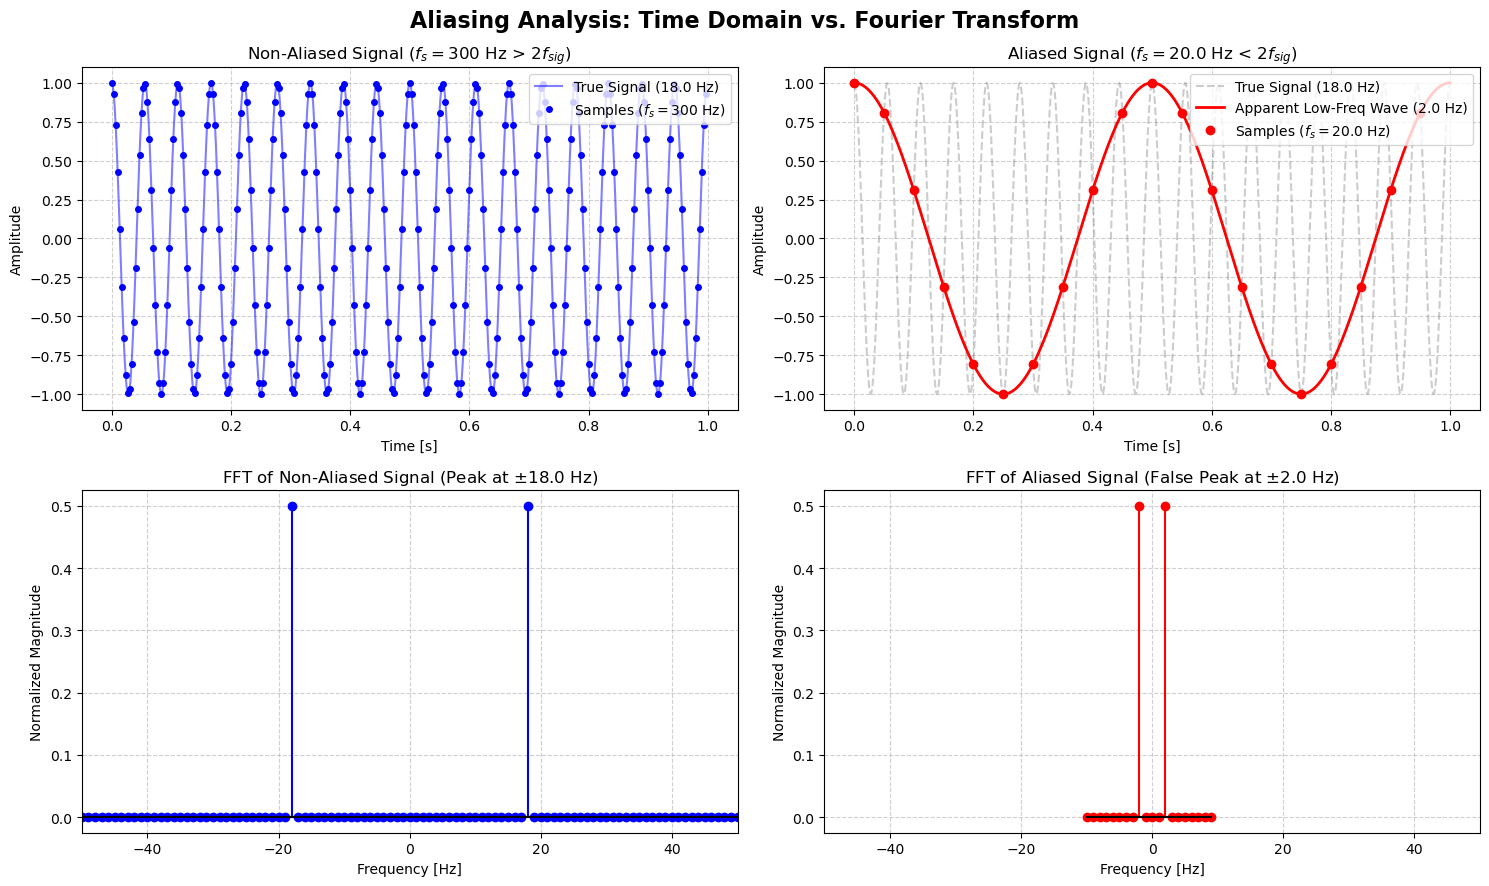

In [25]:
import numpy as np
import matplotlib.pyplot as plt

f_signal = 18.0      # True signal frequency in Hz
duration = 1.0       # Duration in seconds (shows multiple full cycles)

# Sampling frequencies
fs_unaliased = 300 # Above Nyquist (2 * 18 = 36 Hz) -> No Aliasing
fs_aliased = 20.0    # Below Nyquist -> Aliased


# Dense continuous time array for smooth underlying sinusoidal curves
t_dense = np.linspace(0, duration, 1000)
signal_dense = np.cos(2 * np.pi * f_signal * t_dense)

# Sampled time arrays
t_unaliased = np.arange(0, duration, 1.0 / fs_unaliased)
signal_unaliased = np.cos(2 * np.pi * f_signal * t_unaliased)

t_aliased = np.arange(0, duration, 1.0 / fs_aliased)
signal_aliased = np.cos(2 * np.pi * f_signal * t_aliased)

# Apparent aliased frequency: |f_signal - fs_aliased| = |18 - 20| = 2 Hz
f_aliased_apparent = np.abs(f_signal - fs_aliased)
signal_apparent = np.cos(2 * np.pi * f_aliased_apparent * t_dense)


# Unaliased FFT (Normalized magnitude)
fft_unaliased = np.fft.fftshift(np.fft.fft(signal_unaliased)) / len(t_unaliased)
freq_unaliased = np.fft.fftshift(np.fft.fftfreq(len(t_unaliased), d=1.0/fs_unaliased))

# Aliased FFT (Normalized magnitude)
fft_aliased = np.fft.fftshift(np.fft.fft(signal_aliased)) / len(t_aliased)
freq_aliased = np.fft.fftshift(np.fft.fftfreq(len(t_aliased), d=1.0/fs_aliased))


fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle("Aliasing Analysis: Time Domain vs. Fourier Transform", fontsize=16, fontweight='bold')


axes[0, 0].plot(t_dense, signal_dense, 'b-', alpha=0.5, label=f'True Signal ({f_signal} Hz)')
axes[0, 0].plot(t_unaliased, signal_unaliased, 'bo', markersize=4, label=f'Samples ($f_s = {fs_unaliased}$ Hz)')
axes[0, 0].set_title(f"Non-Aliased Signal ($f_s = {fs_unaliased}$ Hz > $2f_{{sig}}$)")
axes[0, 0].set_xlabel("Time [s]")
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend(loc='upper right')


axes[0, 1].plot(t_dense, signal_dense, 'gray', linestyle='--', alpha=0.4, label=f'True Signal ({f_signal} Hz)')
axes[0, 1].plot(t_dense, signal_apparent, 'r-', linewidth=2, label=f'Apparent Low-Freq Wave ({f_aliased_apparent} Hz)')
axes[0, 1].plot(t_aliased, signal_aliased, 'ro', markersize=6, label=f'Samples ($f_s = {fs_aliased}$ Hz)')
axes[0, 1].set_title(f"Aliased Signal ($f_s = {fs_aliased}$ Hz < $2f_{{sig}}$)")
axes[0, 1].set_xlabel("Time [s]")
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend(loc='upper right')


axes[1, 0].stem(freq_unaliased, np.abs(fft_unaliased), linefmt='b-', markerfmt='bo', basefmt='k-')
axes[1, 0].set_title(f"FFT of Non-Aliased Signal (Peak at $\pm{f_signal}$ Hz)")
axes[1, 0].set_xlabel("Frequency [Hz]")
axes[1, 0].set_ylabel("Normalized Magnitude")
axes[1, 0].set_xlim(-50, 50)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)


axes[1, 1].stem(freq_aliased, np.abs(fft_aliased), linefmt='r-', markerfmt='ro', basefmt='k-')
axes[1, 1].set_title(f"FFT of Aliased Signal (False Peak at $\pm{f_aliased_apparent}$ Hz)")
axes[1, 1].set_xlabel("Frequency [Hz]")
axes[1, 1].set_ylabel("Normalized Magnitude")
axes[1, 1].set_xlim(-50, 50)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("prob3.png", dpi=300, bbox_inches='tight')
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

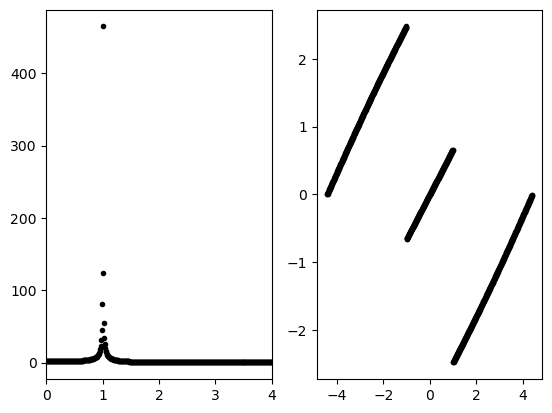

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

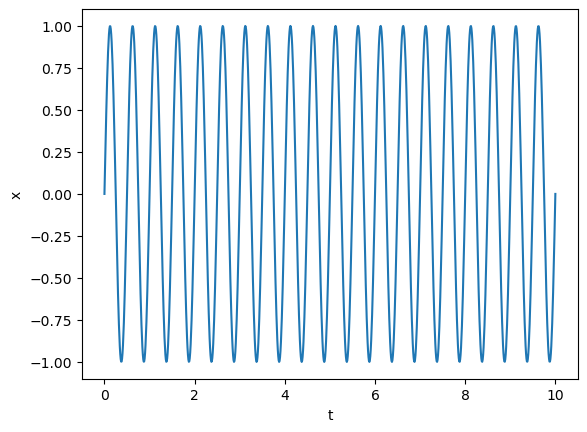

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

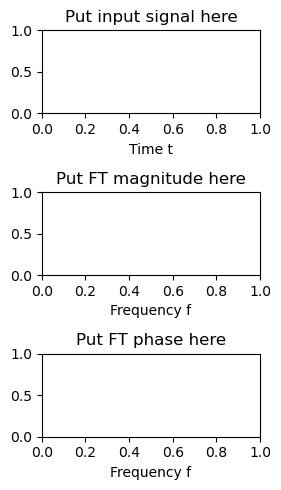

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

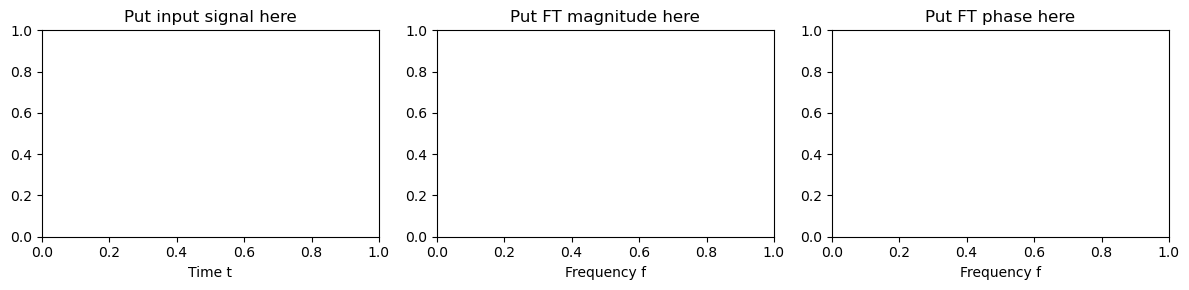

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

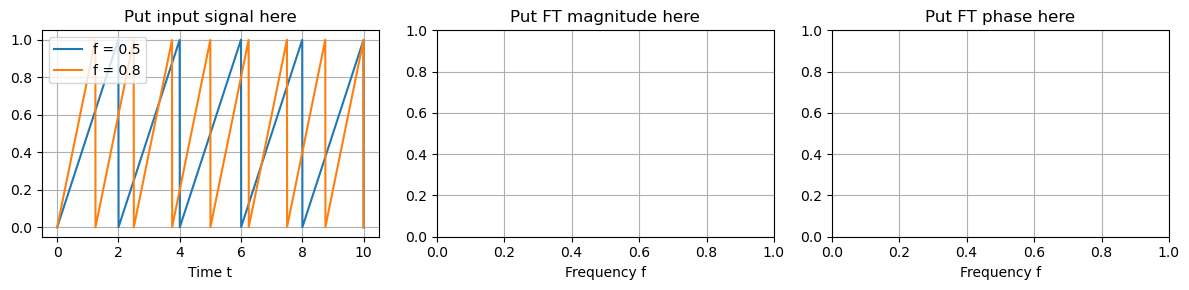

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



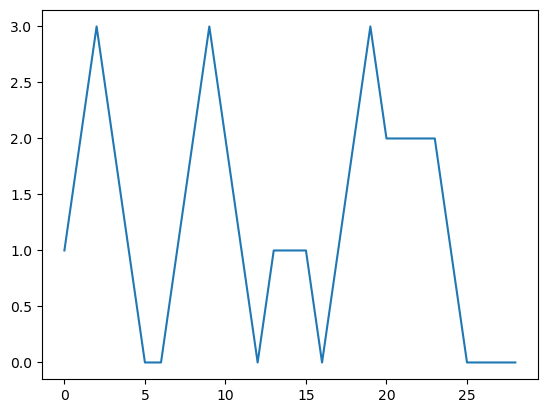

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

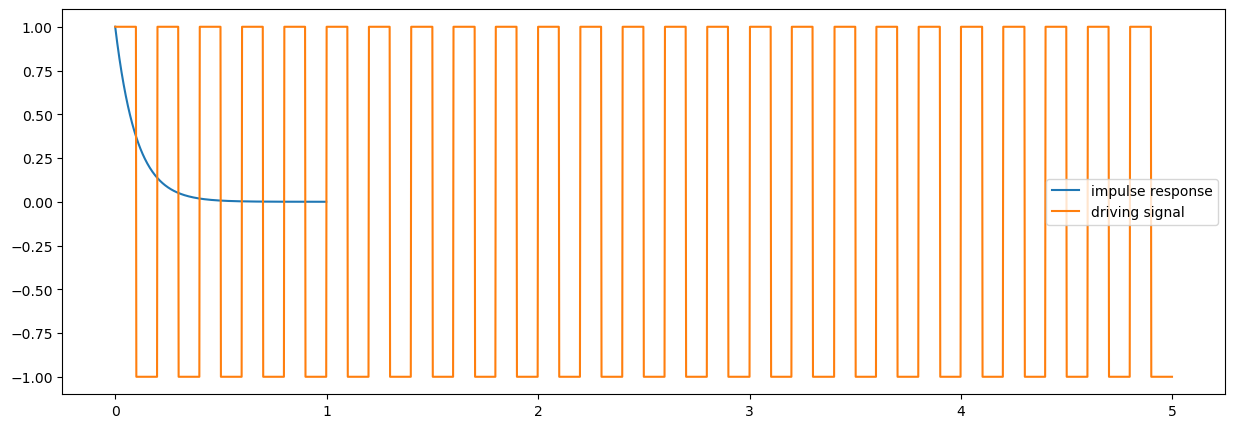

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

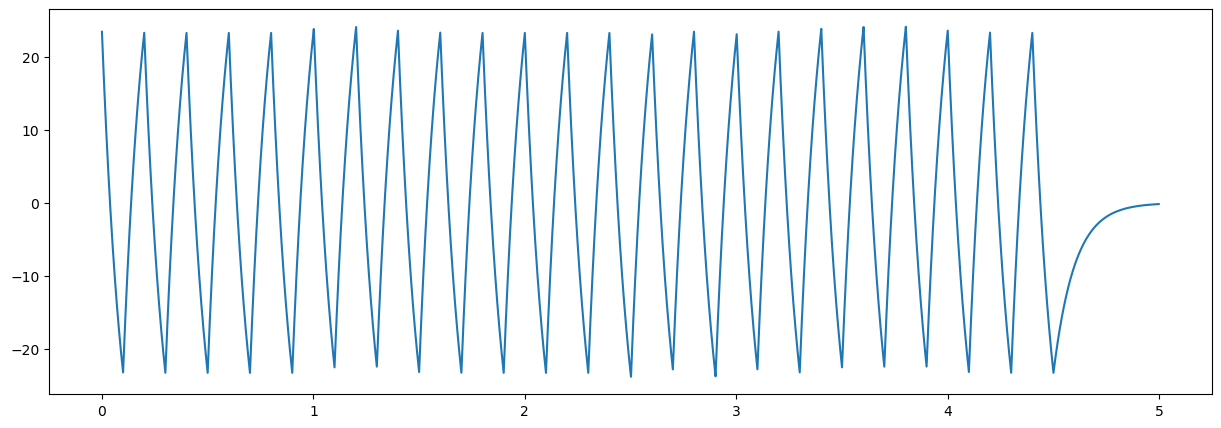

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

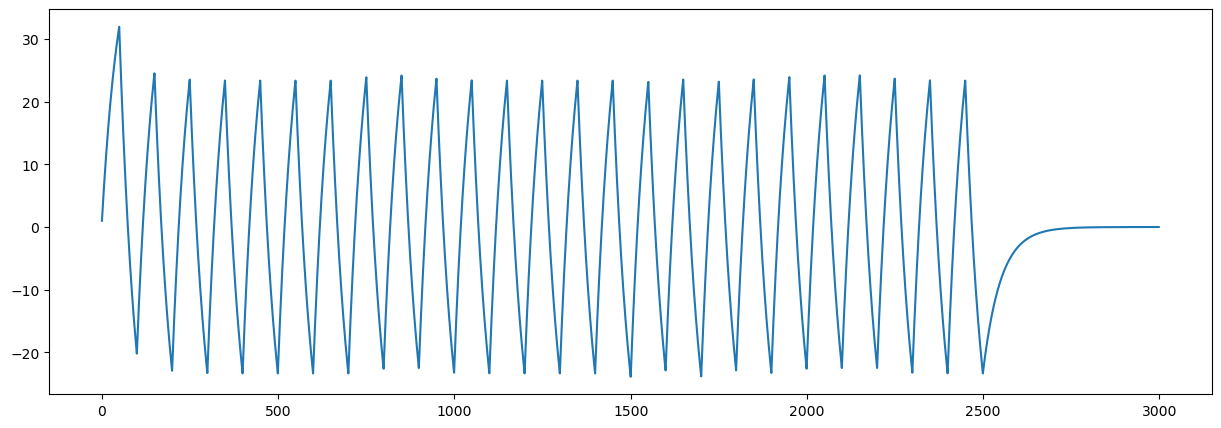

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)